# Experimento 12 — YOLO11n sobre os recortes sem macrófago com aumento de cor HED

- Autor: Clésio Gonçalves
- Criado em: 18 nov. 2026

**Objetivo:** repetir o exp08 (YOLO11n sobre os recortes com o macrófago mascarado; mAP50 0,485 ± 0,109) mudando **um único fator**: **aumento de dados**: além do jitter HSV, cada imagem de treino tem 80% de chance de receber uma perturbação de coloração no espaço HED (Tellez et al., 2018), com fator multiplicativo U(0,9; 1,1) e deslocamento U(−0,02; 0,02) por canal. A região mascarada continua preta. Validação e teste não são alterados.

**Hipótese:** Em vez de igualar a cor das imagens (exp11), ensinar o modelo a ignorar a cor, mostrando no treino variações de coloração (clarear, escurecer, deslocar entre roxo e rosa). Verificado depois: essa intensidade não reproduz o tom acinzentado da leish_1 e da leish_4.

**Por que partir do exp08:** os exp08, exp09 e exp10 mostraram que o tamanho e a geração do modelo não mudam o resultado (0,485 a 0,493). O YOLO11n treina cerca de 5× mais rápido que os modelos large, então as variações de pré-processamento são testadas com ele.

| | |
|---|---|
| **Dataset** | `02_datasets_derivados/03_recortes_512_sem_macrofago/` (gerado por `01_preprocessamento/03_mascarar_macrofago_nos_recortes.ipynb`) |
| **Folds YOLO** | `05_novos_experimentos/exp12_yolo11n_aumento_hed/folds_yolo/` (montados por este notebook, com links simbólicos para o dataset) |
| **Runs** | `05_novos_experimentos/exp12_yolo11n_aumento_hed/runs/fold_1..fold_6/` |
| **Base** | exp08 (`03_experimentos anteriores/exp08_yolo11n_sem_macrofago/`) |

**Configuração:** `yolo11n.pt`, 150 épocas, patience 40, batch 16, AdamW, lr0 5e-4, lrf 0.01, cos_lr, single_cls, seed 42; aumento de dados hsv 0.03/0.9/0.6, degrees 15, flipud 0.5, mixup 0.1, mais os padrões do Ultralytics; imgsz 512; aumento de cor HED.

**Validação:** os mesmos 6 folds por lâmina dos experimentos anteriores (5 lâminas de treino, 1 de validação e 2 de teste; ver `01_preprocessamento/divisao_folds_por_lamina.jpeg`), com métricas agregadas por fold e por lâmina.

## Resultado

**mAP50 0,496 ± 0,124** (exp08: 0,485 ± 0,109; Δ +0,011) · mAP50-95 0,190 ± 0,042 · P 0,514 · R 0,555

- mAP50 0,496 ± 0,124, +0,011 em relação ao exp08. É a maior média da série, mas ainda dentro do ruído. Foi melhor em 4 dos 6 folds.
- Melhorou a leish_1 (+0,047) e a leish_7 (0,688). Piorou a leish_2 (−0,052) e a leish_4 (−0,020).
- A piora na leish_4 é coerente com a limitação vista nas figuras: nesta intensidade, o aumento não gera o tom acinzentado dessa lâmina.
- Conclusão: ganho pequeno e não conclusivo. Próximos testes possíveis: intensidade maior, perturbar também a saturação, ou combinar com a normalização do exp11.

Detalhes por fold e por lâmina: `README.html` desta pasta.


## Utilização da GPU

In [1]:
!nvidia-smi

Wed Nov 18 08:51:57 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.99.02              Driver Version: 595.99.02      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 5070 Ti     Off |   00000000:01:00.0  On |                  N/A |
| 44%   50C    P1             50W /  300W |    1299MiB /  16303MiB |      3%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"


# Importações e parâmetros gerais

In [3]:
import shutil
import yaml
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cv2
from pathlib import Path
from PIL import Image

import torch
from ultralytics import YOLO

import warnings
warnings.filterwarnings('ignore')

# Bloqueia logs de C++ (INFO e WARNING)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_MLIR_ENABLE_MLIR_HAL_TARGET_ EXECUTABLE_DUMP_PATH'] = ''
os.environ['MLIR_CRASH_REPRODUCER_DIRECTORY'] = ''


In [4]:
# Versões dos pacotes usados neste jupyter notebook
%reload_ext watermark
%watermark -a "Clésio Gonçalves" --iversions
!python --version
!conda -V


Author: Clésio Gonçalves

PIL        : 12.0.0
cv2        : 4.13.0
matplotlib : 3.10.6
numpy      : 2.3.5
pandas     : 2.3.3
torch      : 2.12.1
ultralytics: 8.4.75
yaml       : 6.0.3

Python 3.13.9


conda 26.1.1


In [5]:
torch.cuda.is_available()

True

## Parâmetros do sistema

In [6]:
# Diretório raiz
diretorio_raiz = Path("/mnt/arquivos/Doutorado")


## Estrutura do Dataset

- 8 lâminas anotadas no formato YOLO; recortes 512×512 centrados em macrófagos infectados: recortes 512×512 com a bbox do macrófago pintada de preto (mesmo dataset do exp08).
- Classes do `obj.names` (mantido igual ao original): `0 Non-macrophages`, `1 macrophage` (ausente: região apagada), `2 leishmania` (**alvo**: fora do macrófago), `3 inside-macrophage` (ausente).
- Só a classe `leishmania` é usada, remapeada para o índice `0` (detector de classe única).

![Divisão dos folds por lâmina](../01_preprocessamento/divisao_folds_por_lamina.jpeg)

## Parâmetros do experimento

In [7]:
# Diretório deste experimento (na raiz do projeto)
diretorio_experimento = os.path.join(diretorio_raiz, "05_novos_experimentos", "exp12_yolo11n_aumento_hed")

# Dataset: recortes 512×512 com a bbox do macrófago pintada de preto (mesmo dataset do exp08)
# (gerado por 01_preprocessamento/03_mascarar_macrofago_nos_recortes.ipynb)
diretorio_recortes = os.path.join(diretorio_raiz, "02_datasets_derivados", "03_recortes_512_sem_macrofago")

# Tamanho de treino/inferência = tamanho original do recorte, sem upscaling
tamanho_imagem = 512
extensao = '.png'

# Classes do dataset de recortes (mesma ordem do obj.names)
caminho_obj_names = os.path.join(diretorio_recortes, "obj.names")
with open(caminho_obj_names) as f:
    classes_originais = [linha.strip() for linha in f]

# Apenas leishmania FORA do macrófago é a classe de interesse (single-class detector)
nome_classe_interesse = 'leishmania'
indice_classe_interesse = classes_originais.index(nome_classe_interesse)
print(f"Classes originais: {classes_originais}")
print(f"Índice de '{nome_classe_interesse}' (classe de interesse): {indice_classe_interesse}")

# Estrutura YOLO por fold e runs ficam dentro da pasta do experimento
diretorio_yolo_folds = os.path.join(diretorio_experimento, "folds_yolo")
diretorio_runs = os.path.join(diretorio_experimento, "runs")
os.makedirs(diretorio_yolo_folds, exist_ok=True)
os.makedirs(diretorio_runs, exist_ok=True)

# Pesos pré-treinados do YOLO11-nano (cópia local; baixados pela Ultralytics se faltarem)
caminho_pesos_pretreinados = os.path.join(diretorio_experimento, 'yolo11n.pt')
if not os.path.isfile(caminho_pesos_pretreinados):
    caminho_pesos_pretreinados = 'yolo11n.pt'

tamanho_batch = 16

# Hiperparâmetros de treinamento: idênticos ao exp08
parametros_treino = dict(
    epochs=150,
    patience=40,
    imgsz=tamanho_imagem,
    batch=tamanho_batch,
    device=0,
    seed=42,
    workers=8,
    cos_lr=True,
    single_cls=True,
    verbose=False,
    optimizer='AdamW',
    lr0=0.0005,
    lrf=0.01,
    # aumento de dados: jitter de cor (imagens em RGB), rotação, flip vertical (sem orientação
    # canônica em microscopia) e mixup; mosaico, flip horizontal, translação e escala seguem o padrão.
    hsv_h=0.03,
    hsv_s=0.9,
    hsv_v=0.6,
    degrees=15.0,
    flipud=0.5,
    mixup=0.1,
)

Classes originais: ['Non-macrophages', 'macrophage', 'leishmania', 'inside-macrophage']
Índice de 'leishmania' (classe de interesse): 2


## Definição dos 6 folds (idêntica aos experimentos anteriores, para comparação direta)

In [8]:
folds = [
    {'fold': 1, 'treino': ['leish_1', 'leish_2', 'leish_7', 'leish_8', 'leish_9'], 'validacao': ['leish_4'], 'teste': ['leish_3', 'leish_5']},
    {'fold': 2, 'treino': ['leish_1', 'leish_3', 'leish_4', 'leish_5', 'leish_9'], 'validacao': ['leish_8'], 'teste': ['leish_2', 'leish_7']},
    {'fold': 3, 'treino': ['leish_2', 'leish_3', 'leish_4', 'leish_5', 'leish_7'], 'validacao': ['leish_9'], 'teste': ['leish_1', 'leish_8']},
    {'fold': 4, 'treino': ['leish_1', 'leish_2', 'leish_3', 'leish_5', 'leish_8'], 'validacao': ['leish_7'], 'teste': ['leish_4', 'leish_9']},
    {'fold': 5, 'treino': ['leish_3', 'leish_4', 'leish_5', 'leish_8', 'leish_9'], 'validacao': ['leish_2'], 'teste': ['leish_1', 'leish_7']},
    {'fold': 6, 'treino': ['leish_3', 'leish_4', 'leish_5', 'leish_7', 'leish_9'], 'validacao': ['leish_1'], 'teste': ['leish_2', 'leish_8']},
]

pd.DataFrame(folds).set_index('fold')


,treino,validacao,teste
fold,,,
1,"[leish_1, leish_2, leish_7, leish_8, leish_9]",[leish_4],"[leish_3, leish_5]"
2,"[leish_1, leish_3, leish_4, leish_5, leish_9]",[leish_8],"[leish_2, leish_7]"
3,"[leish_2, leish_3, leish_4, leish_5, leish_7]",[leish_9],"[leish_1, leish_8]"
4,"[leish_1, leish_2, leish_3, leish_5, leish_8]",[leish_7],"[leish_4, leish_9]"
5,"[leish_3, leish_4, leish_5, leish_8, leish_9]",[leish_2],"[leish_1, leish_7]"
6,"[leish_3, leish_4, leish_5, leish_7, leish_9]",[leish_1],"[leish_2, leish_8]"


## Construção da estrutura de dataset YOLO para cada fold

In [9]:
# Filtra as anotações de um .txt YOLO, mantendo só a classe de interesse e remapeando-a para o índice 0
def remapeia_anotacoes_classe_unica(txt_origem, indice_classe_interesse):
    linhas_novas = []
    if os.path.isfile(txt_origem):
        with open(txt_origem) as f:
            for linha in f:
                linha = linha.strip()
                if not linha:
                    continue
                partes = linha.split()
                if int(partes[0]) == indice_classe_interesse:
                    linhas_novas.append("0 " + " ".join(partes[1:]))
    return linhas_novas


# Cria link simbólico de uma imagem e grava o .txt remapeado (classe única) na pasta de destino
def linka_imagem_e_anotacao(arquivo, pasta_origem, pasta_img_destino, pasta_lbl_destino, indice_classe_interesse):
    nome_base = os.path.splitext(arquivo)[0]

    img_origem = os.path.join(pasta_origem, arquivo)
    img_destino = os.path.join(pasta_img_destino, arquivo)
    if not os.path.exists(img_destino):
        os.symlink(img_origem, img_destino)

    txt_origem = os.path.join(pasta_origem, f"{nome_base}.txt")
    linhas = remapeia_anotacoes_classe_unica(txt_origem, indice_classe_interesse)
    with open(os.path.join(pasta_lbl_destino, f"{nome_base}.txt"), 'w') as f:
        f.write("\n".join(linhas))
        if linhas:
            f.write("\n")


# Monta a estrutura YOLO (images/labels) de um fold: treino, validação, teste (agregado) e teste por lâmina
def monta_dataset_fold(fold, diretorio_recortes, diretorio_yolo_folds, indice_classe_interesse, extensao):
    diretorio_fold = os.path.join(diretorio_yolo_folds, f"fold_{fold['fold']}")
    if os.path.isdir(diretorio_fold):
        shutil.rmtree(diretorio_fold)

    for papel, laminas in [('train', fold['treino']), ('val', fold['validacao']), ('test', fold['teste'])]:
        pasta_img_destino = os.path.join(diretorio_fold, 'images', papel)
        pasta_lbl_destino = os.path.join(diretorio_fold, 'labels', papel)
        os.makedirs(pasta_img_destino, exist_ok=True)
        os.makedirs(pasta_lbl_destino, exist_ok=True)

        for lamina in laminas:
            pasta_origem = os.path.join(diretorio_recortes, lamina)

            if papel == 'test':
                # subpasta individual da lâmina (usada no diagnóstico por lâmina do conjunto de teste)
                pasta_img_lamina = os.path.join(diretorio_fold, 'images', 'test_lamina', lamina)
                pasta_lbl_lamina = os.path.join(diretorio_fold, 'labels', 'test_lamina', lamina)
                os.makedirs(pasta_img_lamina, exist_ok=True)
                os.makedirs(pasta_lbl_lamina, exist_ok=True)

            for arquivo in sorted(os.listdir(pasta_origem)):
                if not arquivo.endswith(extensao):
                    continue
                linka_imagem_e_anotacao(arquivo, pasta_origem, pasta_img_destino, pasta_lbl_destino, indice_classe_interesse)
                if papel == 'test':
                    linka_imagem_e_anotacao(arquivo, pasta_origem, pasta_img_lamina, pasta_lbl_lamina, indice_classe_interesse)

    return diretorio_fold


for fold in folds:
    diretorio_fold = monta_dataset_fold(fold, diretorio_recortes, diretorio_yolo_folds, indice_classe_interesse, extensao)
    n_train = len(os.listdir(os.path.join(diretorio_fold, 'images', 'train')))
    n_val = len(os.listdir(os.path.join(diretorio_fold, 'images', 'val')))
    n_test = len(os.listdir(os.path.join(diretorio_fold, 'images', 'test')))
    print(f"Fold {fold['fold']}: treino={n_train} | validação={n_val} | teste={n_test}")


Fold 1: treino=1064 | validação=126 | teste=378


Fold 2: treino=808 | validação=353 | teste=407


Fold 3: treino=911 | validação=208 | teste=449


Fold 4: treino=954 | validação=280 | teste=334


Fold 5: treino=1065 | validação=127 | teste=376


Fold 6: treino=992 | validação=96 | teste=480


## Geração dos arquivos `data.yaml` por fold

In [10]:
# Grava o data.yaml de um fold. Se 'test_split' for informado, aponta o "test" para uma subpasta específica (lâmina única)
def gera_data_yaml(diretorio_fold, nome_classe, caminho_yaml, test_split='test'):
    conteudo = {
        'path': str(diretorio_fold),
        'train': 'images/train',
        'val': 'images/val',
        'test': f'images/{test_split}',
        'nc': 1,
        'names': {0: nome_classe},
    }
    with open(caminho_yaml, 'w') as f:
        yaml.safe_dump(conteudo, f, sort_keys=False, allow_unicode=True)
    return caminho_yaml


caminhos_yaml = {}        # data.yaml agregado (teste = todas as lâminas do fold)
caminhos_yaml_lamina = {} # data.yaml por lâmina de teste, usado no diagnóstico

for fold in folds:
    n = fold['fold']
    diretorio_fold = os.path.join(diretorio_yolo_folds, f"fold_{n}")

    caminhos_yaml[n] = gera_data_yaml(
        diretorio_fold, nome_classe_interesse,
        os.path.join(diretorio_fold, 'data.yaml'),
    )

    for lamina in fold['teste']:
        caminhos_yaml_lamina[(n, lamina)] = gera_data_yaml(
            diretorio_fold, nome_classe_interesse,
            os.path.join(diretorio_fold, f'data_test_{lamina}.yaml'),
            test_split=f'test_lamina/{lamina}',
        )

print(f"{len(caminhos_yaml)} data.yaml agregados e {len(caminhos_yaml_lamina)} data.yaml por lâmina de teste gerados.")


6 data.yaml agregados e 12 data.yaml por lâmina de teste gerados.


## Aumento de cor no espaço HED (fator testado neste experimento)

O Ultralytics não tem aumento de coloração por corante. A classe abaixo é inserida no pipeline de aumento de dados do treino, logo antes do jitter HSV. Ela converte a imagem para o espaço HED (`skimage.color.rgb2hed`), multiplica cada canal por um fator de U(1 − 0,1; 1 + 0,1), soma um deslocamento de U(−0,02; 0,02) e volta para RGB. Pixels pretos (região do macrófago mascarada) continuam pretos.

A troca é feita substituindo `v8_transforms` no módulo `ultralytics.data.dataset`. Isso vale só para o conjunto de treino (validação e teste usam `LetterBox`, sem aumento) e também depois do `close_mosaic`, que reconstrói as transformações com a mesma função.

In [11]:
from skimage.color import rgb2hed, hed2rgb
import ultralytics.data.dataset as modulo_dataset_ultralytics
from ultralytics.data.augment import v8_transforms as v8_transforms_original


class AumentoHED:
    """Perturbação de coloração no espaço HED (Tellez et al., 2018). Recebe e devolve o dicionário de rótulos do Ultralytics."""

    def __init__(self, sigma_fator=0.1, sigma_desloc=0.02, p=0.8):
        self.sigma_fator = sigma_fator
        self.sigma_desloc = sigma_desloc
        self.p = p

    def __call__(self, rotulos):
        if random.random() >= self.p:
            return rotulos
        img_bgr = rotulos['img']
        mascara_preta = img_bgr.max(axis=2) == 0
        hed = rgb2hed(img_bgr[..., ::-1].astype(np.float32) / 255)
        fator = np.random.uniform(1 - self.sigma_fator, 1 + self.sigma_fator, 3)
        desloc = np.random.uniform(-self.sigma_desloc, self.sigma_desloc, 3)
        rgb = np.clip(hed2rgb(hed * fator + desloc), 0, 1)
        saida = (rgb[..., ::-1] * 255).round().astype(np.uint8)
        saida[mascara_preta] = 0
        rotulos['img'] = np.ascontiguousarray(saida)
        return rotulos


def v8_transforms_com_hed(dataset, imgsz, hyp, stretch=False):
    transformacoes = v8_transforms_original(dataset, imgsz, hyp, stretch)
    # ordem original: [pré (mosaico+afim), MixUp, CutMix, Albumentations, RandomHSV, flip vertical, flip horizontal]
    transformacoes.insert(4, AumentoHED())
    return transformacoes


modulo_dataset_ultralytics.v8_transforms = v8_transforms_com_hed
print("Aumento HED ativado no pipeline de treino.")

Aumento HED ativado no pipeline de treino.


## Treinamento dos 6 folds (YOLO11-nano, batch=16)

Treinamento local na GPU a partir do checkpoint pré-treinado `yolo11n.pt`. Se o `best.pt` de um fold já existir **e** o arquivo `fold_N/concluido.txt` indicar que o treino terminou, o fold é pulado.

In [12]:
caminhos_best = {}

for fold in folds:
    n = fold['fold']
    nome_run = f"fold_{n}"
    caminho_best = os.path.join(diretorio_runs, nome_run, 'weights', 'best.pt')

    marcador = os.path.join(diretorio_runs, nome_run, 'concluido.txt')
    if os.path.isfile(caminho_best) and os.path.isfile(marcador):
        print(f"Fold {n}: pesos já existem em '{caminho_best}'. Treinamento ignorado.")
    else:
        modelo = YOLO(caminho_pesos_pretreinados)
        modelo.train(
            data=caminhos_yaml[n],
            project=diretorio_runs,
            name=nome_run,
            exist_ok=True,
            **parametros_treino,
        )
        with open(marcador, 'w') as f:
            f.write('treino concluído\n')
        print(f"Fold {n}: treinamento concluído. Pesos em '{caminho_best}'.")
        del modelo
        torch.cuda.empty_cache()

    caminhos_best[n] = caminho_best


New https://pypi.org/project/ultralytics/8.4.215 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.75 🚀 Python-3.13.9 torch-2.12.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 15819MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/mnt/arquivos/Doutorado/05_novos_experimentos/exp12_yolo11n_aumento_hed/folds_yolo/fold_1/data.yaml, degrees=15.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.03, hsv_s=0.9, hsv_v=0.6, imgsz=512, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=/mnt/arquivos/Doutorado/05_novos_experimentos/exp12_yolo11n_aumento_hed/yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=fold_1, nbs=64, nms=False, opset=None, optimi

Overriding class names with single class.


Overriding model.yaml nc=80 with nc=1



                   from  n    params  module                                       arguments                     


... (19,683 outputs left out)

                   all         96        831      0.661      0.561      0.598      0.273


Speed: 0.0ms preprocess, 0.3ms inference, 0.0ms loss, 1.0ms postprocess per image


Results saved to /mnt/arquivos/Doutorado/05_novos_experimentos/exp12_yolo11n_aumento_hed/runs/fold_6


Fold 6: treinamento concluído. Pesos em '/mnt/arquivos/Doutorado/05_novos_experimentos/exp12_yolo11n_aumento_hed/runs/fold_6/weights/best.pt'.


## Avaliação no conjunto de teste — agregada por fold

In [13]:
# Extrai as métricas de detecção relevantes de um resultado de model.val()
def extrai_metricas(resultado_val):
    rd = resultado_val.results_dict
    return {
        'precisao': rd.get('metrics/precision(B)', float('nan')),
        'recall': rd.get('metrics/recall(B)', float('nan')),
        'mAP50': rd.get('metrics/mAP50(B)', float('nan')),
        'mAP50-95': rd.get('metrics/mAP50-95(B)', float('nan')),
    }


linhas_metricas_fold = []

for fold in folds:
    n = fold['fold']
    modelo = YOLO(caminhos_best[n])
    resultado = modelo.val(data=caminhos_yaml[n], split='test', imgsz=tamanho_imagem, plots=False, verbose=False)

    metricas = extrai_metricas(resultado)
    metricas['fold'] = n
    metricas['laminas_teste'] = ", ".join(fold['teste'])
    linhas_metricas_fold.append(metricas)

df_metricas_fold = pd.DataFrame(linhas_metricas_fold).set_index('fold')
df_metricas_fold = df_metricas_fold[['laminas_teste', 'precisao', 'recall', 'mAP50', 'mAP50-95']]
df_metricas_fold


Ultralytics 8.4.75 🚀 Python-3.13.9 torch-2.12.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 15819MiB)


YOLO11n summary (fused): 101 layers, 2,582,347 parameters, 0 gradients, 6.3 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5827.0±1194.6 MB/s, size: 219.2 KB)


val: Scanning /mnt/arquivos/Doutorado/05_novos_experimentos/exp12_yolo11n_aumento_hed/folds_yolo/fold_1/labels/test... 378 images, 52 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 378/378 5.6Kit/s 0.1s

val: New cache created: /mnt/arquivos/Doutorado/05_novos_experimentos/exp12_yolo11n_aumento_hed/folds_yolo/fold_1/labels/test.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 4% ──────────── 1/24 2.3it/s 0.1s<9.9s

... (68 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 30/30 45.0it/s 0.7s

                   all        480       1634      0.379       0.46      0.349      0.137


Speed: 0.2ms preprocess, 0.5ms inference, 0.0ms loss, 0.2ms postprocess per image


,laminas_teste,precisao,recall,mAP50,mAP50-95
fold,,,,,
1,"leish_3, leish_5",0.564862,0.590804,0.556353,0.190978
2,"leish_2, leish_7",0.602570,0.624615,0.606990,0.229283
3,"leish_1, leish_8",0.414481,0.458981,0.359471,0.146741
4,"leish_4, leish_9",0.467314,0.585892,0.469641,0.196708
5,"leish_1, leish_7",0.653698,0.610469,0.636539,0.239890
6,"leish_2, leish_8",0.378906,0.459974,0.349444,0.137432


In [14]:
# Média aritmética e desvio padrão de cada métrica entre os 6 folds
resumo_metricas = df_metricas_fold[['precisao', 'recall', 'mAP50', 'mAP50-95']].agg(['mean', 'std']).T
resumo_metricas.columns = ['média', 'desvio_padrão']
resumo_metricas.round(4)


,média,desvio_padrão
precisao,0.5136,0.1098
recall,0.5551,0.0754
mAP50,0.4964,0.1237
mAP50-95,0.1902,0.0417


## Comparação com os experimentos anteriores

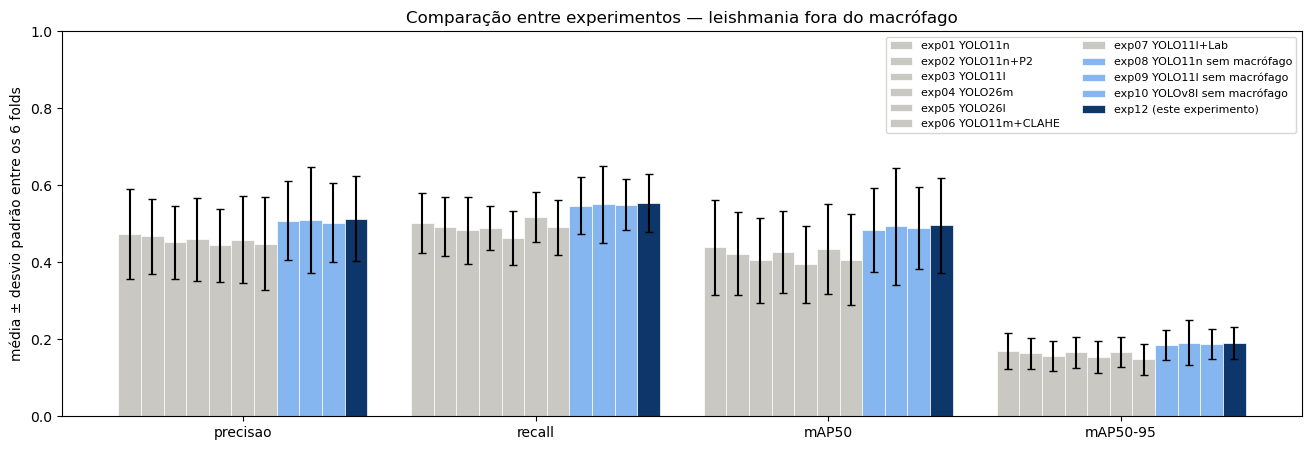

In [15]:
%matplotlib inline
# Médias e desvios padrão dos experimentos anteriores (numeração do resumo_experimentos.html).
# exp01-07: recortes com o macrófago visível; exp08-10: recortes com o macrófago mascarado.
# A base direta deste experimento é o exp08 (YOLO11n): só um fator muda.
anteriores = {
    'exp01 YOLO11n':               ((0.4735, 0.1164), (0.5012, 0.0780), (0.4391, 0.1229), (0.1695, 0.0457)),
    'exp02 YOLO11n+P2':            ((0.4672, 0.0981), (0.4922, 0.0763), (0.4226, 0.1083), (0.1640, 0.0405)),
    'exp03 YOLO11l':               ((0.4520, 0.0945), (0.4832, 0.0864), (0.4048, 0.1095), (0.1576, 0.0391)),
    'exp04 YOLO26m':               ((0.4595, 0.1079), (0.4894, 0.0567), (0.4272, 0.1068), (0.1659, 0.0396)),
    'exp05 YOLO26l':               ((0.4442, 0.0946), (0.4632, 0.0705), (0.3943, 0.1000), (0.1538, 0.0417)),
    'exp06 YOLO11m+CLAHE':         ((0.4581, 0.1132), (0.5170, 0.0652), (0.4345, 0.1175), (0.1670, 0.0391)),
    'exp07 YOLO11l+Lab':           ((0.4485, 0.1206), (0.4904, 0.0707), (0.4067, 0.1180), (0.1483, 0.0407)),
    'exp08 YOLO11n sem macrófago': ((0.5077, 0.1022), (0.5471, 0.0743), (0.4850, 0.1090), (0.1841, 0.0391)),
    'exp09 YOLO11l sem macrófago': ((0.5098, 0.1364), (0.5508, 0.1003), (0.4930, 0.1516), (0.1915, 0.0588)),
    'exp10 YOLOv8l sem macrófago': ((0.5029, 0.1033), (0.5491, 0.0664), (0.4889, 0.1065), (0.1876, 0.0381)),
}
metricas_plot = ['precisao', 'recall', 'mAP50', 'mAP50-95']

nomes_exp = list(anteriores) + ['exp12 (este experimento)']
medias_exp = [[m for m, _ in v] for v in anteriores.values()] + [list(resumo_metricas.loc[metricas_plot, 'média'])]
desvios_exp = [[d for _, d in v] for v in anteriores.values()] + [list(resumo_metricas.loc[metricas_plot, 'desvio_padrão'])]

# cinza = macrófago visível; azul claro = mascarado (exp08-10); azul escuro = este experimento
cores = ['#c9c8c2'] * 7 + ['#86b6ef'] * (len(anteriores) - 7) + ['#0d366b']

x = np.arange(len(metricas_plot))
n_exp = len(nomes_exp)
largura = 0.85 / n_exp
fig, ax = plt.subplots(figsize=(16, 5))
for i, (nome, media, desvio) in enumerate(zip(nomes_exp, medias_exp, desvios_exp)):
    deslocamento = (i - (n_exp - 1) / 2) * largura
    ax.bar(x + deslocamento, media, largura, yerr=desvio, capsize=3, label=nome, color=cores[i], edgecolor='white', linewidth=0.5)

ax.set_xticks(x)
ax.set_xticklabels(metricas_plot)
ax.set_ylim(0, 1)
ax.set_ylabel('média ± desvio padrão entre os 6 folds')
ax.set_title('Comparação entre experimentos — leishmania fora do macrófago')
ax.legend(loc='upper right', fontsize=8, ncol=2)
plt.show()

## Diagnóstico por lâmina (conjunto de teste)

In [16]:
linhas_metricas_lamina = []

for (n, lamina), caminho_yaml_lamina in caminhos_yaml_lamina.items():
    modelo = YOLO(caminhos_best[n])
    resultado = modelo.val(data=caminho_yaml_lamina, split='test', imgsz=tamanho_imagem, plots=False, verbose=False)

    metricas = extrai_metricas(resultado)
    metricas['fold'] = n
    metricas['lamina'] = lamina
    linhas_metricas_lamina.append(metricas)

df_metricas_lamina = pd.DataFrame(linhas_metricas_lamina)[['lamina', 'fold', 'precisao', 'recall', 'mAP50', 'mAP50-95']]
df_metricas_lamina.sort_values(['lamina', 'fold']).reset_index(drop=True)


Ultralytics 8.4.75 🚀 Python-3.13.9 torch-2.12.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 15819MiB)


YOLO11n summary (fused): 101 layers, 2,582,347 parameters, 0 gradients, 6.3 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3624.5±494.6 MB/s, size: 219.9 KB)


val: Scanning /mnt/arquivos/Doutorado/05_novos_experimentos/exp12_yolo11n_aumento_hed/folds_yolo/fold_1/labels/test_lamina/leish_3... 17 images, 11 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 17/17 5.8Kit/s 0.0s

val: New cache created: /mnt/arquivos/Doutorado/05_novos_experimentos/exp12_yolo11n_aumento_hed/folds_yolo/fold_1/labels/test_lamina/leish_3.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 20.2it/s 0.1s

... (118 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 45.0it/s 0.5s

                   all        353        992      0.406      0.463      0.354       0.14


Speed: 0.1ms preprocess, 0.5ms inference, 0.0ms loss, 0.2ms postprocess per image


,lamina,fold,precisao,recall,mAP50,mAP50-95
0,leish_1,3,0.624120,0.512635,0.545691,0.242138
1,leish_1,5,0.688899,0.530686,0.599253,0.249977
2,leish_2,2,0.363230,0.448598,0.332887,0.127974
3,leish_2,6,0.369500,0.549844,0.361543,0.142917
4,leish_3,1,0.428462,0.400000,0.316090,0.134246
5,leish_4,4,0.195864,0.372743,0.164413,0.070144
6,leish_5,1,0.570483,0.591111,0.560245,0.192236
7,leish_7,2,0.667452,0.682873,0.689624,0.259708
8,leish_7,5,0.683074,0.659658,0.686681,0.254082
9,leish_8,3,0.379607,0.490986,0.355751,0.138701


In [17]:
# Resumo por lâmina: média e desvio padrão entre as vezes em que a lâmina caiu no teste (1 ou 2 folds)
resumo_lamina = df_metricas_lamina.groupby('lamina')[['precisao', 'recall', 'mAP50', 'mAP50-95']].agg(['mean', 'std', 'count'])
resumo_lamina.round(4)


precisao                recall                 mAP50                \
            mean     std count    mean     std count    mean     std count   
lamina                                                                       
leish_1   0.6565  0.0458     2  0.5217  0.0128     2  0.5725  0.0379     2   
leish_2   0.3664  0.0044     2  0.4992  0.0716     2  0.3472  0.0203     2   
leish_3   0.4285     NaN     1  0.4000     NaN     1  0.3161     NaN     1   
leish_4   0.1959     NaN     1  0.3727     NaN     1  0.1644     NaN     1   
leish_5   0.5705     NaN     1  0.5911     NaN     1  0.5602     NaN     1   
leish_7   0.6753  0.0110     2  0.6713  0.0164     2  0.6882  0.0021     2   
leish_8   0.3930  0.0189     2  0.4768  0.0200     2  0.3550  0.0011     2   
leish_9   0.5457     NaN     1  0.6673     NaN     1  0.5749     NaN     1   

        mAP50-95                
            mean     std count  
lamina                          
leish_1   0.2461  0.0055     2  
leish_2   0.1354  0.0106     2  
leish_3   0.1342     NaN     1  
leish_4   0.0701     NaN     1  
leish_5   0.1922     NaN     1  
leish_7   0.2569  0.0040     2  
leish_8   0.1391  0.0006     2  
leish_9   0.2411     NaN     1

## Comparação visual: anotação do especialista vs. detecção da YOLO

Em cada imagem: caixas **amarelas** = anotação original do especialista (classe `leishmania`, remapeada); caixas **vermelhas** = detecções do modelo (com confiança). Amostras da lâmina com melhor e da lâmina com pior mAP50 no diagnóstico acima. Imagens em RGB puro (região do macrófago aparece preta, mascarada no pré-processamento).

In [18]:
# Lê as caixas (em pixels) de um .txt YOLO (classe única já remapeada)
def le_boxes_pixel(txt_path, largura, altura):
    boxes = []
    if os.path.isfile(txt_path):
        with open(txt_path) as f:
            for linha in f:
                linha = linha.strip()
                if not linha:
                    continue
                _, xc, yc, w, h = map(float, linha.split())
                boxes.append((xc * largura, yc * altura, w * largura, h * altura))
    return boxes


# Desenha, sobre o mesmo eixo, as caixas do especialista (amarelo) e as detecções do modelo (vermelho)
def desenha_comparacao(eixo, caminho_imagem, caminho_label, modelo, conf=0.25):
    img_bgr = cv2.imread(caminho_imagem)
    altura, largura = img_bgr.shape[:2]
    eixo.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))

    gt_boxes = le_boxes_pixel(caminho_label, largura, altura)
    for xc, yc, w, h in gt_boxes:
        eixo.add_patch(patches.Rectangle((xc - w / 2, yc - h / 2), w, h, linewidth=1.5, edgecolor='yellow', facecolor='none'))

    resultado = modelo.predict(caminho_imagem, conf=conf, imgsz=tamanho_imagem, verbose=False)[0]
    for caixa in resultado.boxes:
        x1, y1, x2, y2 = caixa.xyxy[0].tolist()
        confianca = float(caixa.conf[0])
        eixo.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=1.5, edgecolor='red', facecolor='none'))
        eixo.text(x1, max(y1 - 4, 0), f"{confianca:.2f}", color='red', fontsize=7, va='bottom')

    eixo.set_title(f"{os.path.basename(caminho_imagem)}\nespecialista={len(gt_boxes)} | YOLO={len(resultado.boxes)}", fontsize=8)
    eixo.axis('off')


def fold_para_lamina(lamina):
    for fold in folds:
        if lamina in fold['teste']:
            return fold['fold']


Melhor lâmina (mAP50): leish_7 | Pior lâmina (mAP50): leish_4


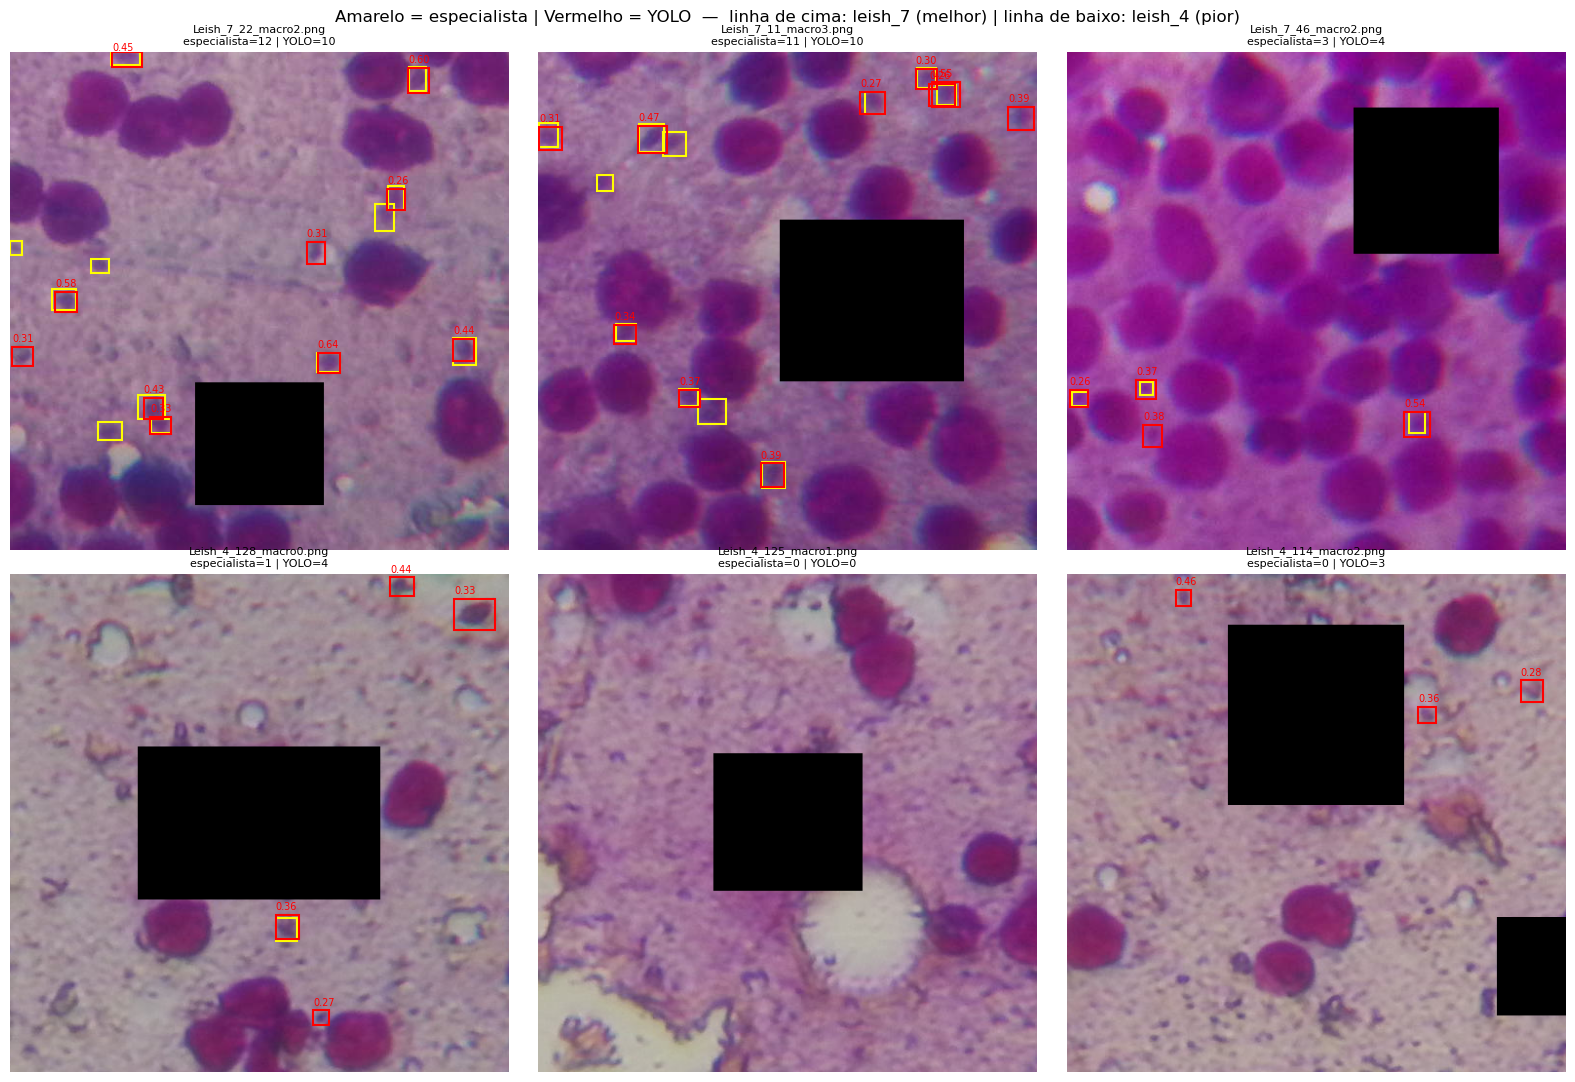

In [19]:
%matplotlib inline
melhor_lamina = resumo_lamina[('mAP50', 'mean')].idxmax()
pior_lamina = resumo_lamina[('mAP50', 'mean')].idxmin()
print(f"Melhor lâmina (mAP50): {melhor_lamina} | Pior lâmina (mAP50): {pior_lamina}")

cache_modelos = {}
def obter_modelo(n_fold):
    if n_fold not in cache_modelos:
        cache_modelos[n_fold] = YOLO(caminhos_best[n_fold])
    return cache_modelos[n_fold]

amostras_comparacao = []
random.seed(42)
for lamina in [melhor_lamina, pior_lamina]:
    n_fold = fold_para_lamina(lamina)
    pasta_img = os.path.join(diretorio_yolo_folds, f"fold_{n_fold}", 'images', 'test_lamina', lamina)
    pasta_lbl = os.path.join(diretorio_yolo_folds, f"fold_{n_fold}", 'labels', 'test_lamina', lamina)
    imagens = sorted(f for f in os.listdir(pasta_img) if f.endswith(extensao))
    escolhidas = random.sample(imagens, min(3, len(imagens)))
    for img_nome in escolhidas:
        amostras_comparacao.append((n_fold, lamina, pasta_img, pasta_lbl, img_nome))

fig, eixos = plt.subplots(2, 3, figsize=(16, 11))
for eixo, (n_fold, lamina, pasta_img, pasta_lbl, img_nome) in zip(eixos.ravel(), amostras_comparacao):
    modelo = obter_modelo(n_fold)
    nome_base = os.path.splitext(img_nome)[0]
    desenha_comparacao(eixo, os.path.join(pasta_img, img_nome), os.path.join(pasta_lbl, f"{nome_base}.txt"), modelo)

fig.suptitle(f"Amarelo = especialista | Vermelho = YOLO  —  linha de cima: {melhor_lamina} (melhor) | linha de baixo: {pior_lamina} (pior)")
plt.tight_layout()
plt.show()
